In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
from src import config as C

# 03 - Baseline models (TF-IDF + LR / Linear SVM / Naive Bayes)
Training is done by `python -m src.train_baselines` (about 2-3 minutes on one CPU core). This notebook shows the stored results.

In [2]:
res = pd.read_csv(C.RESULTS_DIR / 'baseline_results.csv')
ov = res[res.subset == 'Overall']
display(ov[['model','best_param','val_macro_f1','accuracy','precision_scam','recall_scam','macro_f1','weighted_f1','macro_f1_ci_low','macro_f1_ci_high','train_seconds','latency_single_ms_mean']].round(4))

,model,best_param,val_macro_f1,accuracy,precision_scam,recall_scam,macro_f1,weighted_f1,macro_f1_ci_low,macro_f1_ci_high,train_seconds,latency_single_ms_mean
0,TFIDF-word + LogisticRegression,10.00,0.9427,0.9690,0.8938,0.9226,0.9446,0.9692,0.8575,0.9873,0.1812,0.5285
8,TFIDF-word + LinearSVM,0.10,0.9404,0.9861,0.9931,0.9226,0.9741,0.9859,0.9481,0.9890,0.1366,0.4661
16,TFIDF-word + NaiveBayes,0.01,0.9176,0.9369,0.7927,0.8387,0.8885,0.9376,0.7503,0.9672,0.1359,0.5753
24,TFIDF-char + LogisticRegression,100.00,0.9489,0.9872,0.9931,0.9290,0.9762,0.9870,0.9520,0.9897,1.0023,0.6669
32,TFIDF-char + LinearSVM,0.10,0.9552,0.9861,0.9931,0.9226,0.9741,0.9859,0.9489,0.9882,0.8094,0.6954
40,TFIDF-char + NaiveBayes,0.01,0.9277,0.9283,0.7500,0.8516,0.8770,0.9301,0.7182,0.9667,0.9545,0.9674
48,TFIDF-word + LogisticRegression (aug-trained),10.00,0.9374,0.9369,0.7500,0.9290,0.8956,0.9395,0.7303,0.9861,1.8850,0.5564
56,TFIDF-word + LinearSVM (aug-trained),10.00,0.9433,0.9401,0.7592,0.9355,0.9007,0.9425,0.7364,0.9881,1.6495,0.5166
64,TFIDF-word + NaiveBayes (aug-trained),0.01,0.9597,0.9690,0.9375,0.8710,0.9423,0.9685,0.8831,0.9718,1.2517,0.9851
72,TFIDF-char + LogisticRegression (aug-trained),10.00,0.9476,0.9840,0.9730,0.9290,0.9705,0.9838,0.9409,0.9875,8.0887,0.8771


In [3]:
display(res[(res.model_id=='char_lr')][['subset','n','n_scam','n_groups','macro_f1','macro_f1_ci_low','macro_f1_ci_high','status']].round(3))

,subset,n,n_scam,n_groups,macro_f1,macro_f1_ci_low,macro_f1_ci_high,status
24,Overall,935,155,778,0.976,0.952,0.990,ok
25,English,782,96,770,0.963,0.939,0.981,ok
26,Urdu,0,0,0,NaN,NaN,NaN,no samples
27,Roman Urdu,7,6,2,NaN,NaN,NaN,insufficient (n=7 < 30)
28,Mixed/Code-Switched,142,53,4,1.000,0.500,1.000,descriptive only: 4 independent groups (< 20); CI/point estimates unreliable
29,Roman Urdu + Mixed,149,59,5,1.000,0.500,1.000,descriptive only: 5 independent groups (< 20); CI/point estimates unreliable
30,source:UCI,774,96,774,0.963,0.939,0.982,ok
31,source:Zenodo,161,59,4,1.000,0.500,1.000,descriptive only: 4 independent groups (< 20); CI/point estimates unreliable


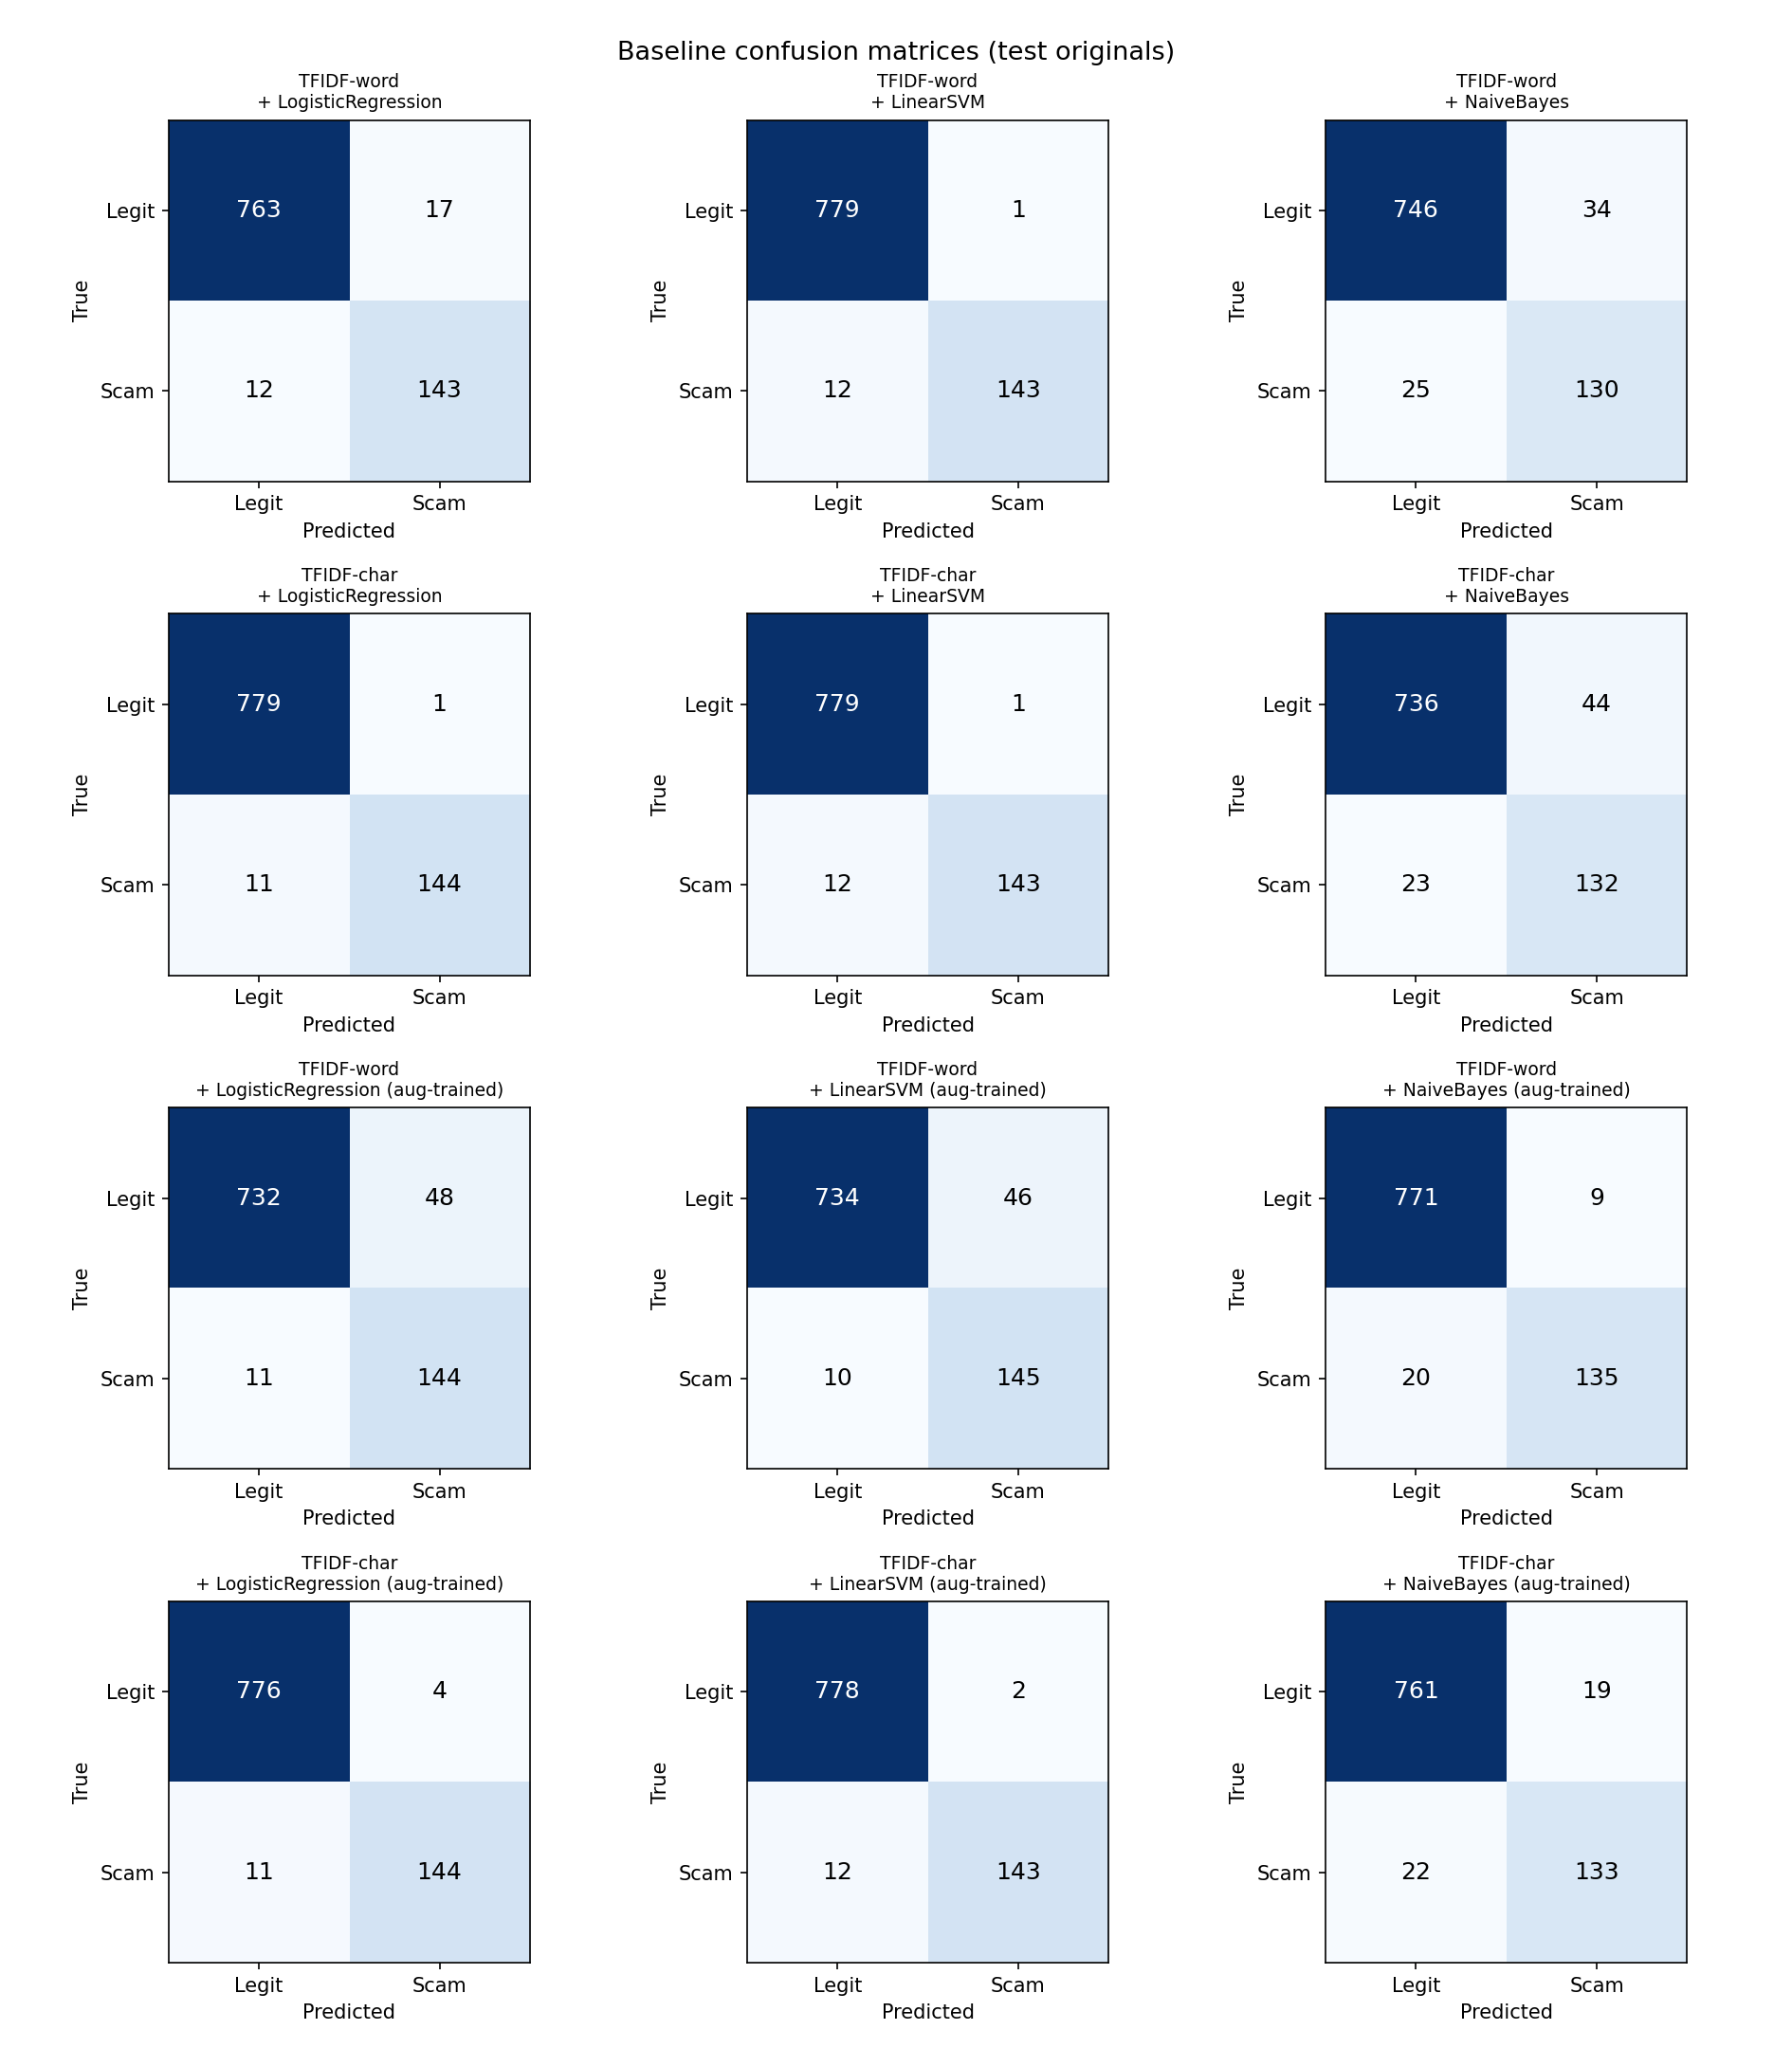

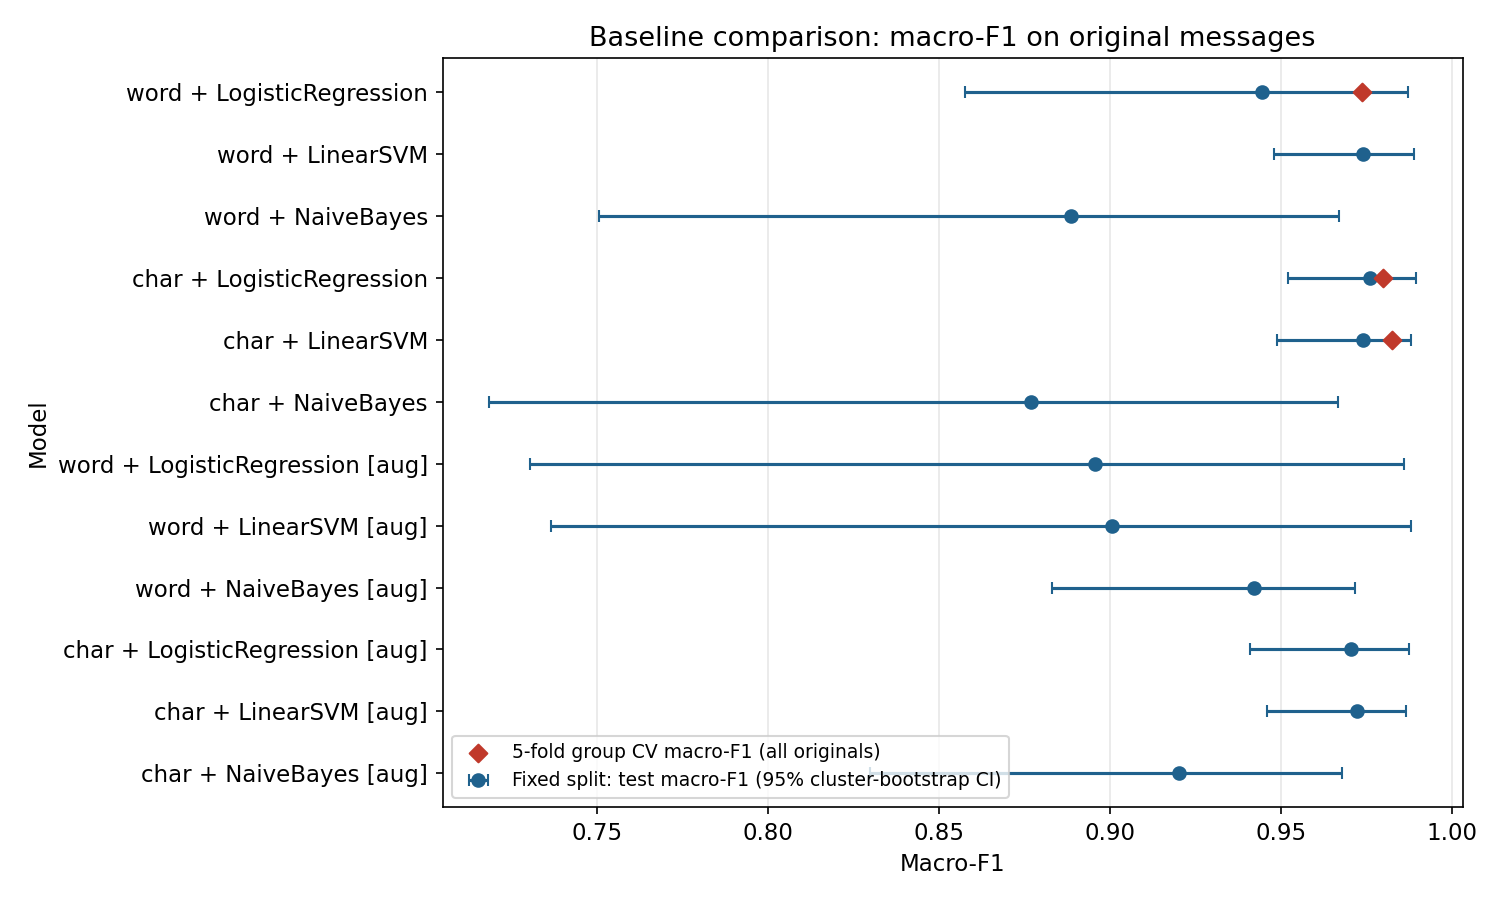

In [4]:
display(Image(str(C.FIGURES_DIR / 'baseline_confusion_matrices.png'), width=800))
display(Image(str(C.FIGURES_DIR / 'results_model_comparison.png'), width=800))

## 5-fold group cross-validation (more reliable for Roman Urdu / Mixed than the fixed split)

In [5]:
cv = pd.read_csv(C.RESULTS_DIR / 'group_cv_results.csv')
display(cv[['model_id','subset','n','n_groups','macro_f1','macro_f1_ci_low','macro_f1_ci_high','status']].round(3))

,model_id,subset,n,n_groups,macro_f1,macro_f1_ci_low,macro_f1_ci_high,status
0,char_lr,Overall,6160,4970,0.980,0.966,0.989,ok
1,char_lr,English,5340,4919,0.980,0.974,0.986,ok
2,char_lr,Roman Urdu,359,10,0.997,0.935,1.000,descriptive only: 10 independent groups (< 20); CI/point estimates unreliable
3,char_lr,Mixed/Code-Switched,430,16,0.940,0.770,1.000,descriptive only: 16 independent groups (< 20); CI/point estimates unreliable
4,char_lr,Roman Urdu + Mixed,789,22,0.968,0.885,1.000,ok
5,char_lr,source:Zenodo,1000,19,0.974,0.906,1.000,descriptive only: 19 independent groups (< 20); CI/point estimates unreliable
6,char_lr,source:UCI,5160,4951,0.980,0.974,0.986,ok
7,word_lr,Overall,6160,4970,0.974,0.960,0.983,ok
8,word_lr,English,5340,4919,0.966,0.958,0.975,ok
9,word_lr,Roman Urdu,359,10,1.000,1.000,1.000,descriptive only: 10 independent groups (< 20); CI/point estimates unreliable
